In [113]:
import numpy as np
import s3fs
import pygrib
import gzip
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import xarray as xr
from scipy.ndimage import gaussian_filter
from cartopy.io.img_tiles import GoogleTiles
import pandas as pd
%matplotlib inline

In [3]:
s3 = s3fs.S3FileSystem(anon=True)

In [102]:
s3.ls("s3://noaa-mrms-pds/")

['noaa-mrms-pds/ALASKA',
 'noaa-mrms-pds/ANC',
 'noaa-mrms-pds/CARIB',
 'noaa-mrms-pds/CONUS',
 'noaa-mrms-pds/ConvectProb',
 'noaa-mrms-pds/GUAM',
 'noaa-mrms-pds/HAWAII',
 'noaa-mrms-pds/ProbSevere',
 'noaa-mrms-pds/index.html']

In [5]:
s3.ls("s3://noaa-mrms-pds/CONUS/MultiSensor_QPE_72H_Pass2_00.00")

['noaa-mrms-pds/CONUS/BREF_1HR_MAX_00.50',
 'noaa-mrms-pds/CONUS/BrightBandBottomHeight_00.00',
 'noaa-mrms-pds/CONUS/BrightBandTopHeight_00.00',
 'noaa-mrms-pds/CONUS/CREF_1HR_MAX_00.50',
 'noaa-mrms-pds/CONUS/EchoTop_18_00.50',
 'noaa-mrms-pds/CONUS/EchoTop_30_00.50',
 'noaa-mrms-pds/CONUS/EchoTop_50_00.50',
 'noaa-mrms-pds/CONUS/EchoTop_60_00.50',
 'noaa-mrms-pds/CONUS/FLASH_CREST_MAXSOILSAT_00.00',
 'noaa-mrms-pds/CONUS/FLASH_CREST_MAXSTREAMFLOW_00.00',
 'noaa-mrms-pds/CONUS/FLASH_CREST_MAXUNITSTREAMFLOW_00.00',
 'noaa-mrms-pds/CONUS/FLASH_HP_MAXSTREAMFLOW_00.00',
 'noaa-mrms-pds/CONUS/FLASH_HP_MAXUNITSTREAMFLOW_00.00',
 'noaa-mrms-pds/CONUS/FLASH_QPE_ARI01H_00.00',
 'noaa-mrms-pds/CONUS/FLASH_QPE_ARI03H_00.00',
 'noaa-mrms-pds/CONUS/FLASH_QPE_ARI06H_00.00',
 'noaa-mrms-pds/CONUS/FLASH_QPE_ARI12H_00.00',
 'noaa-mrms-pds/CONUS/FLASH_QPE_ARI24H_00.00',
 'noaa-mrms-pds/CONUS/FLASH_QPE_ARI30M_00.00',
 'noaa-mrms-pds/CONUS/FLASH_QPE_ARIMAX_00.00',
 'noaa-mrms-pds/CONUS/FLASH_QPE_FFG01H_

In [112]:
s3.ls("s3://noaa-mrms-pds/CONUS/MergedReflectivityQC_00.50/20240331/")

['noaa-mrms-pds/CONUS/MergedReflectivityQC_00.50/20240331/MRMS_MergedReflectivityQC_00.50_20240331-000037.grib2.gz',
 'noaa-mrms-pds/CONUS/MergedReflectivityQC_00.50/20240331/MRMS_MergedReflectivityQC_00.50_20240331-000236.grib2.gz',
 'noaa-mrms-pds/CONUS/MergedReflectivityQC_00.50/20240331/MRMS_MergedReflectivityQC_00.50_20240331-000436.grib2.gz',
 'noaa-mrms-pds/CONUS/MergedReflectivityQC_00.50/20240331/MRMS_MergedReflectivityQC_00.50_20240331-000638.grib2.gz',
 'noaa-mrms-pds/CONUS/MergedReflectivityQC_00.50/20240331/MRMS_MergedReflectivityQC_00.50_20240331-000840.grib2.gz',
 'noaa-mrms-pds/CONUS/MergedReflectivityQC_00.50/20240331/MRMS_MergedReflectivityQC_00.50_20240331-001035.grib2.gz',
 'noaa-mrms-pds/CONUS/MergedReflectivityQC_00.50/20240331/MRMS_MergedReflectivityQC_00.50_20240331-001240.grib2.gz',
 'noaa-mrms-pds/CONUS/MergedReflectivityQC_00.50/20240331/MRMS_MergedReflectivityQC_00.50_20240331-001434.grib2.gz',
 'noaa-mrms-pds/CONUS/MergedReflectivityQC_00.50/20240331/MRMS_M

In [10]:
filename = "s3://noaa-mrms-pds/CONUS/MultiSensor_QPE_72H_Pass2_00.00/20240331/MRMS_MultiSensor_QPE_72H_Pass2_00.00_20240331-230000.grib2.gz"
with s3.open(filename) as f:
    f_data = f.read()

In [14]:
data = pygrib.fromstring(gzip.decompress(f_data))

In [40]:
data.units

'unknown'

In [29]:
lats, lons = data.latlons()

In [42]:
lats.shape

(3500, 7000)

In [57]:
data.values.shape

(3500, 7000)

In [58]:
da = xr.DataArray(data=data.values[::-1], coords={"lat": lats[::-1, 0], "lon": lons[0]})

In [59]:
da["lat"]

<xarray.DataArray 'lat' (lat: 3500)> Size: 28kB
array([20.005001, 20.015   , 20.025   , ..., 54.975   , 54.985   , 54.995   ],
      shape=(3500,))
Coordinates:
  * lat      (lat) float64 28kB 20.01 20.02 20.03 20.04 ... 54.98 54.98 54.99

In [79]:
mrms_la = da.sel(lat=slice(32, 35), lon=slice(239, 244))

In [136]:
data.Ny

3500

In [137]:
data.longitudes[:data.Nx]

array([230.005   , 230.015   , 230.025   , ..., 299.974998, 299.984998,
       299.994998], shape=(7000,))

In [140]:
data.latitudes[::data.Nx]

array([54.995   , 54.985   , 54.975   , ..., 20.025   , 20.015   ,
       20.005001], shape=(3500,))

In [50]:
360 - 117.75

242.25

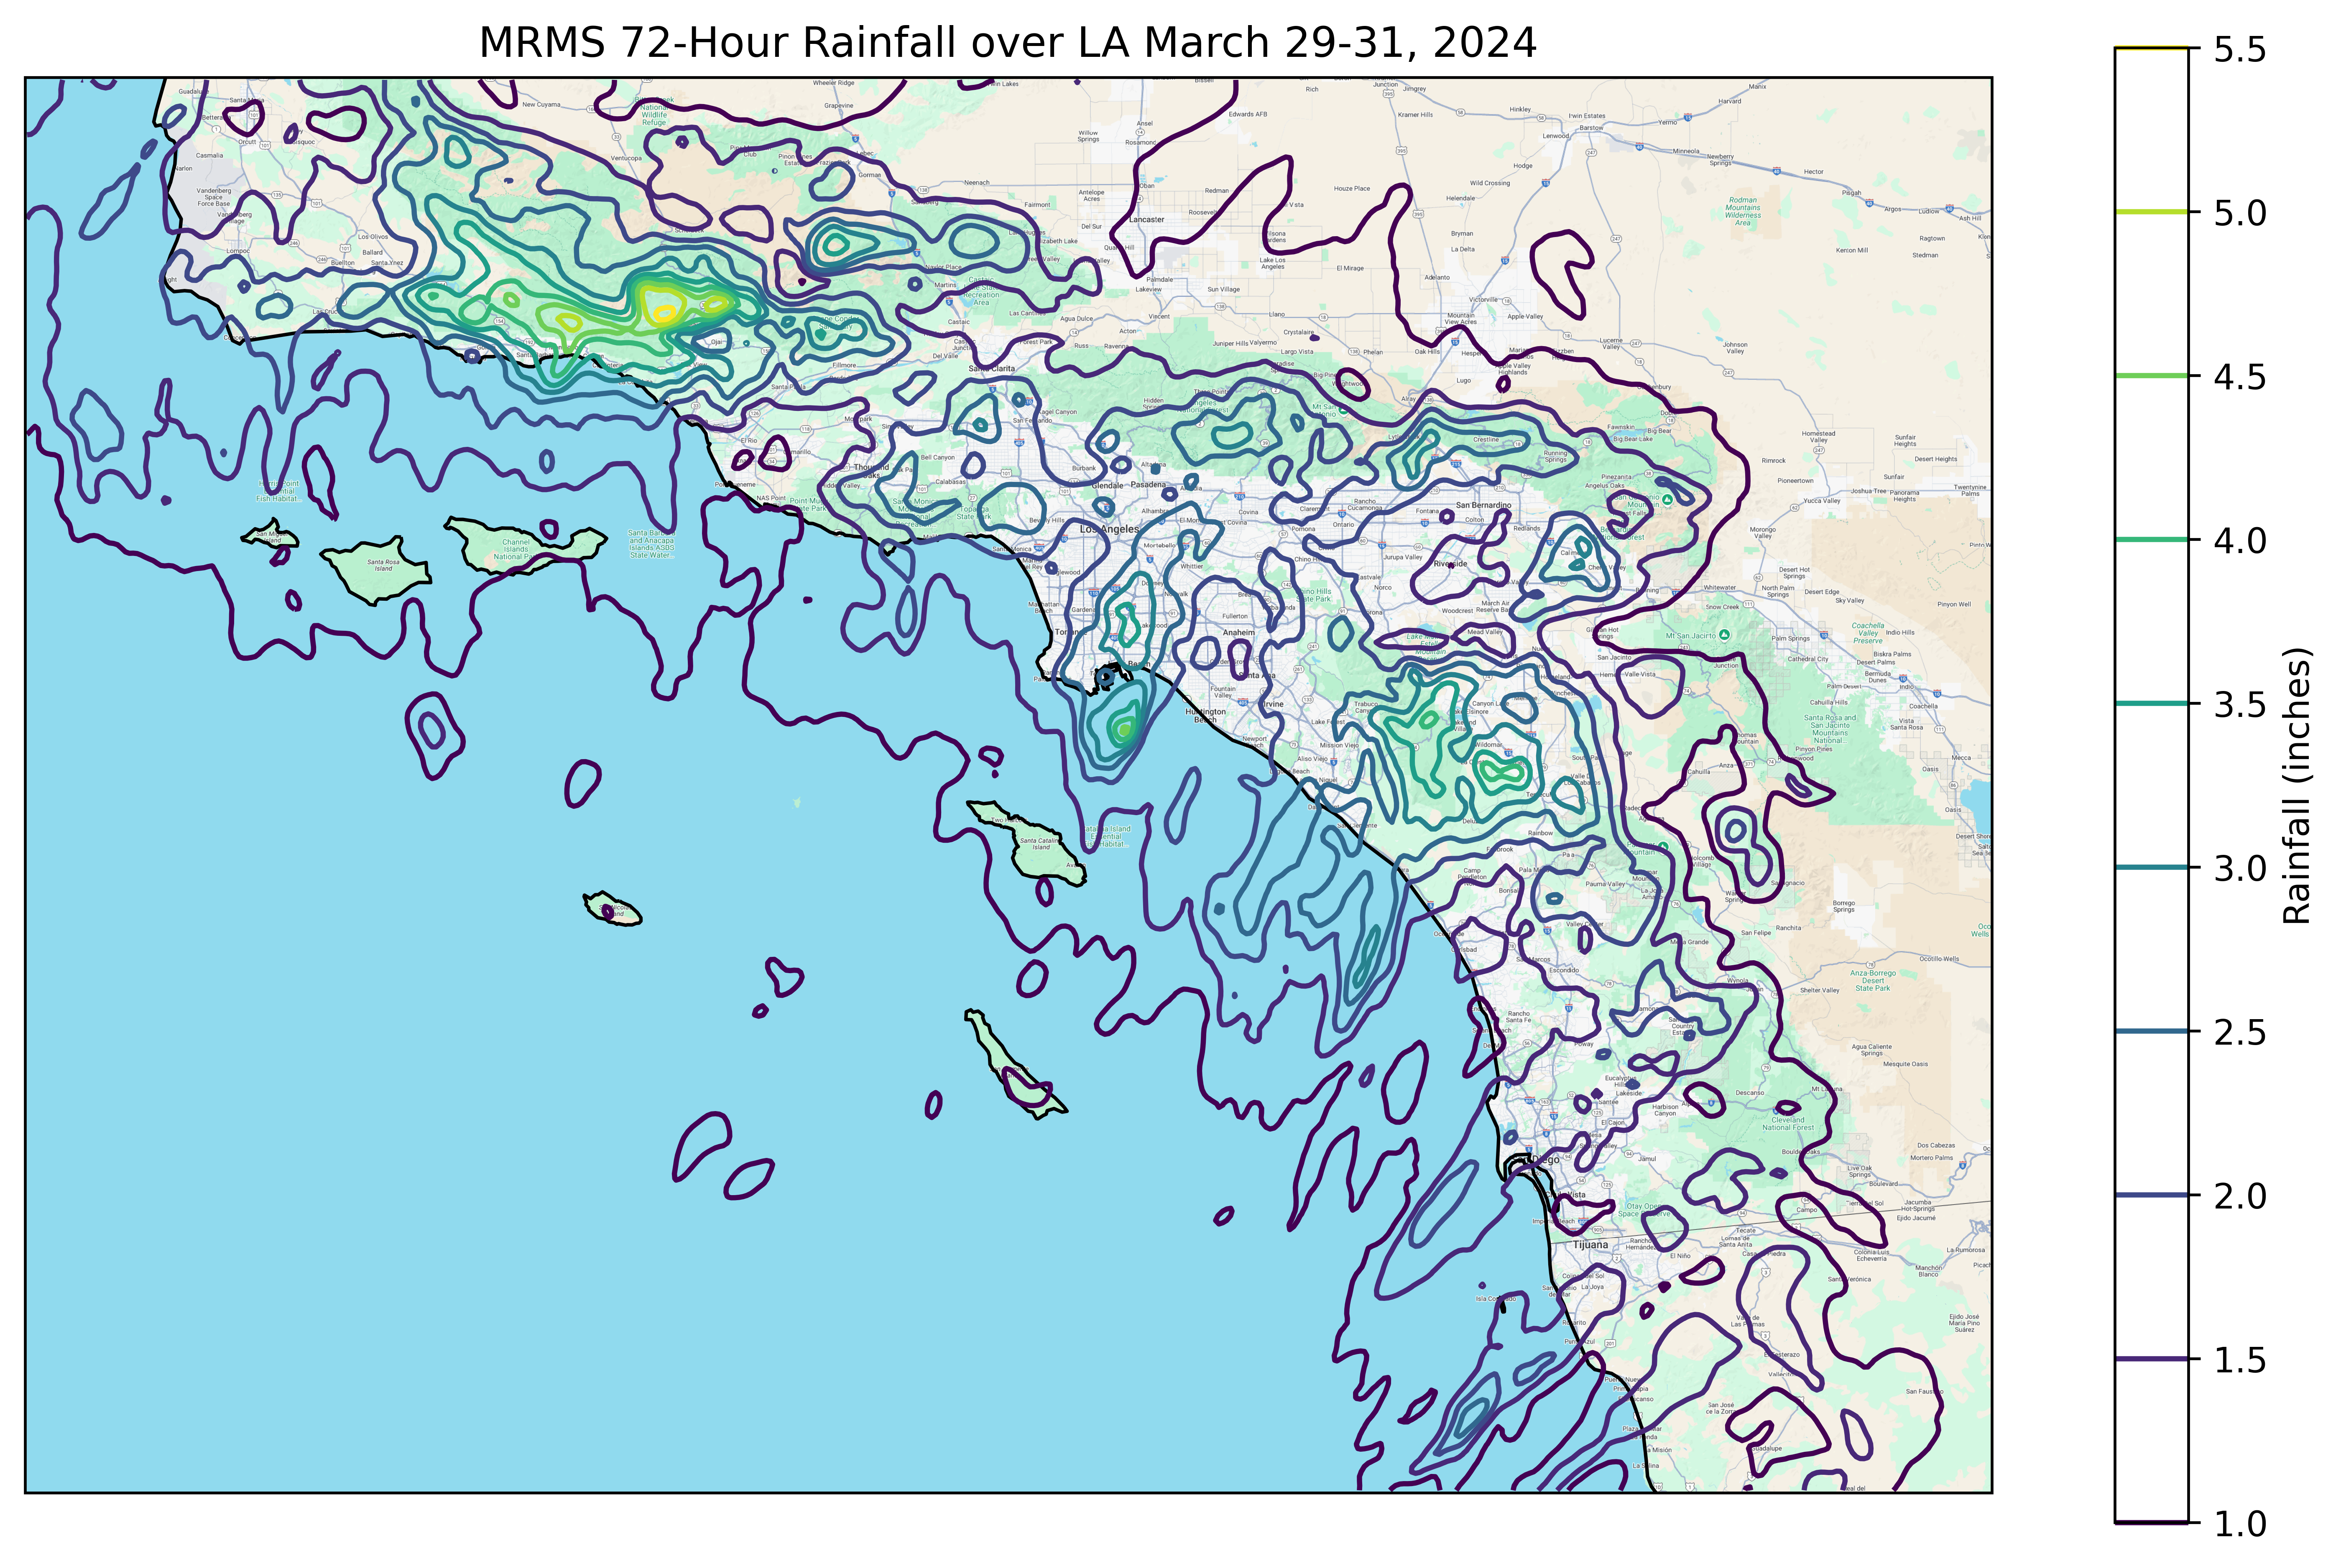

In [101]:
tiler = GoogleTiles(style="street")
mercator = tiler.crs
fig = plt.figure(figsize=(10, 6), dpi=600)

ax = fig.add_axes((0.02, 0.02, 0.98, 0.98), projection=mercator)
ax.set_extent([239, 244, 32, 35], crs=ccrs.PlateCarree())
ax.add_image(tiler, 10)
ax.coastlines("10m")
plt.contour(mrms_la.lon, mrms_la.lat, gaussian_filter(mrms_la.values, 1) / 25.4, np.arange(1, 6, 0.5), 
               transform=ccrs.PlateCarree())
plt.colorbar(label="Rainfall (inches)")
plt.title("MRMS 72-Hour Rainfall over LA March 29-31, 2024")
plt.savefig("mrms_rain_la.png", dpi=600, bbox_inches="tight")

In [175]:
def load_mrms_data(datetime, variable, region="CONUS"):
    grib_table_url = "https://raw.githubusercontent.com/NOAA-National-Severe-Storms-Laboratory/mrms-support/refs/heads/main/GRIB2_TABLES/UserTable_MRMS_v12.2.csv"
    grib_table = pd.read_csv(grib_table_url)
    ts = pd.Timestamp(datetime)
    ts_date_str = ts.strftime("%Y%m%d")
    ts_datetime_str = ts.strftime("%Y%m%d-%H%M%S")
    s3 = s3fs.S3FileSystem(anon=True)
    filename = f"s3://noaa-mrms-pds/{region}/{variable}/{ts_date_str}/MRMS_{variable}_{ts_datetime_str}.grib2.gz"
    with s3.open(filename, "rb") as f:
        f_data = f.read()
    data = pygrib.fromstring(gzip.decompress(f_data))
    grib_attrs = grib_table.loc[(grib_table["Category"] == data["parameterCategory"]) & (grib_table["Parameter"] == data["parameterNumber"])].T.iloc[:, 0].dropna().to_dict()
    xr_data = xr.DataArray(data.values[::-1], coords={"lat":data.latitudes[::data.Nx][::-1], "lon":data.longitudes[:data.Nx], 
                                                }, 
                           name=variable,
                           attrs=grib_attrs)
    return xr_data


In [172]:
data.longitudes[:data.Nx]

array([230.005   , 230.015   , 230.025   , ..., 299.974998, 299.984998,
       299.994998], shape=(7000,))

In [116]:
s3.isfile("s3://noaa-mrms-pds/CONUS/MultiSensor_QPE_72H_Pass2_00.00/20240331/MRMS_MultiSensor_QPE_72H_Pass2_00.00_20240331-2302000.grib2.gz")

False

In [124]:
grib_table = pd.read_csv("https://raw.githubusercontent.com/NOAA-National-Severe-Storms-Laboratory/mrms-support/refs/heads/main/GRIB2_TABLES/UserTable_MRMS_v12.2.csv")

In [176]:
now_data = load_mrms_data("2024-05-06 12:00:00", "MultiSensor_QPE_72H_Pass2_00.00")

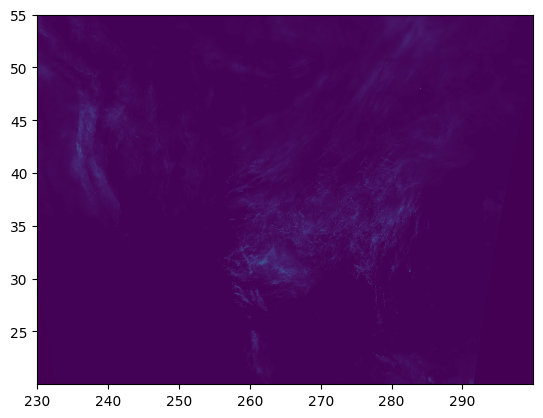

In [179]:
plt.pcolormesh(now_data.lon, now_data.lat, now_data)

In [166]:
s3.ls("noaa-mrms-pds/CONUS/MultiSensor_QPE_72H_Pass2_00.00/20240506")

['noaa-mrms-pds/CONUS/MultiSensor_QPE_72H_Pass2_00.00/20240506/MRMS_MultiSensor_QPE_72H_Pass2_00.00_20240506-000000.grib2.gz',
 'noaa-mrms-pds/CONUS/MultiSensor_QPE_72H_Pass2_00.00/20240506/MRMS_MultiSensor_QPE_72H_Pass2_00.00_20240506-010000.grib2.gz',
 'noaa-mrms-pds/CONUS/MultiSensor_QPE_72H_Pass2_00.00/20240506/MRMS_MultiSensor_QPE_72H_Pass2_00.00_20240506-020000.grib2.gz',
 'noaa-mrms-pds/CONUS/MultiSensor_QPE_72H_Pass2_00.00/20240506/MRMS_MultiSensor_QPE_72H_Pass2_00.00_20240506-030000.grib2.gz',
 'noaa-mrms-pds/CONUS/MultiSensor_QPE_72H_Pass2_00.00/20240506/MRMS_MultiSensor_QPE_72H_Pass2_00.00_20240506-040000.grib2.gz',
 'noaa-mrms-pds/CONUS/MultiSensor_QPE_72H_Pass2_00.00/20240506/MRMS_MultiSensor_QPE_72H_Pass2_00.00_20240506-050000.grib2.gz',
 'noaa-mrms-pds/CONUS/MultiSensor_QPE_72H_Pass2_00.00/20240506/MRMS_MultiSensor_QPE_72H_Pass2_00.00_20240506-060000.grib2.gz',
 'noaa-mrms-pds/CONUS/MultiSensor_QPE_72H_Pass2_00.00/20240506/MRMS_MultiSensor_QPE_72H_Pass2_00.00_20240506-07

In [121]:
data.parameterCategory

6

In [130]:
data.parameterNumber

43

In [128]:
dir(data)

['GRIBEditionNumber',
 'NV',
 'Ni',
 'Nj',
 'PLPresent',
 'PVPresent',
 '__class__',
 '__delattr__',
 '__delitem__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattr__',
 '__getattribute__',
 '__getitem__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__setitem__',
 '__setstate__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '_all_keys',
 '_get_key',
 '_read_only_keys',
 '_reshape_mask',
 '_ro_keys',
 '_set_projparams',
 '_unshape_mask',
 'alternativeRowScanning',
 'analDate',
 'analDate',
 'angleDivisor',
 'angleMultiplier',
 'angleSubdivisions',
 'average',
 'backgroundProcess',
 'basicAngleOfTheInitialProductionDomain',
 'binaryScaleFactor',
 'bitMapIndicator',
 'bitmapPresent',
 'bitsPerValue',
 'bottomLevel',
 'centre',
 'centreDescription',
 'cfName',
 'cfNameECMF',
 'cfVarName',
 'cfVarNameECMF',
 'changeDecimalP